# Text to Image Generation using Stable Diffusionn and Diffusers

In [9]:
pip install diffusers transformers gradio accelerate

In [10]:
from diffusers import StableDiffusionPipeline
import torch
import matplotlib.pyplot as plt

In [11]:
model_id1 = "dreamlike-art/dreamlike-diffusion-1.0"
model_id2 = "stabilityai/stable-diffusion-xl-base-1.0"

pipe = StableDiffusionPipeline.from_pretrained(model_id1, torch_dtype=torch.float16, use_safetensors=True)
pipe = pipe.to("cuda")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model_index.json:   0%|          | 0.00/511 [00:00<?, ?B/s]

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/518 [00:00<?, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (6 outputs left out)

config.json:   0%|          | 0.00/577 [00:00<?, ?B/s]

unet/diffusion_pytorch_model.safetensors:   0%|          | 0.00/1.72G [00:00<?, ?B/s]

vae/diffusion_pytorch_model.safetensors:   0%|          | 0.00/167M [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

In [12]:
prompt = """dreeamlikeart, a grungy woman with rainbow hair, travelling between simensions, dynamic pose, happy, soft eyes and narrow chin,
extreme bokeh, dainty figure, long hair straight down, torn kawaii shirt and baggy jeans
"""

In [13]:
image = pipe(prompt).images[0]

  0%|          | 0/50 [00:00<?, ?it/s]

[PROMPT]:  dreeamlikeart, a grungy woman with rainbow hair, travelling between simensions, dynamic pose, happy, soft eyes and narrow chin,
extreme bokeh, dainty figure, long hair straight down, torn kawaii shirt and baggy jeans



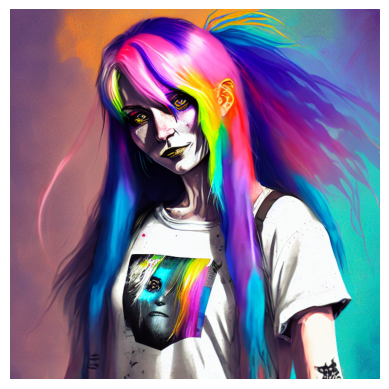

In [14]:
print("[PROMPT]: ",prompt)
plt.imshow(image);
plt.axis('off');

In [15]:
prompt2 = """A girl is sitting on a chair & She is accompanied by her tiger. Make sure to keep it cinematic and color to be golden iris"""
image = pipe(prompt2).images[0]

  0%|          | 0/50 [00:00<?, ?it/s]

[PROMPT]:  A girl is sitting on a chair & She is accompanied by her tiger. Make sure to keep it cinematic and color to be golden iris


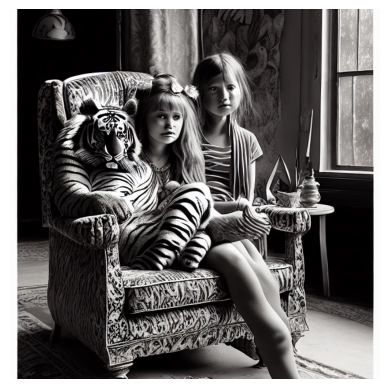

In [16]:
print("[PROMPT]: ",prompt2)
plt.imshow(image);
plt.axis('off');

Working with Stable Diffusion Parameters

*   Neagtive prompting
*   num_interface_steps
*   num_images_per_prompt
*   height
*   weight





In [23]:
def generate_image(pipe, prompt, params):
  img = pipe(prompt, **params).images

  num_images = len(img)
  if num_images>1:
    fig, ax = plt.subplots(nrows=1, ncols=num_images)
    for i in range(num_images):
      ax[i].imshow(img[i]);
      ax[i].axis('off');
  else:
    fig = plt.figure()
    plt.imshow(img[0]);
    plt.axis('off');
    plt.tight_layout()

In [24]:
prompt = "dreamlike, beautiful girl playing the festival of colors, draped in traditional Indian attire, throwing colors"
params = {}

  0%|          | 0/50 [00:00<?, ?it/s]

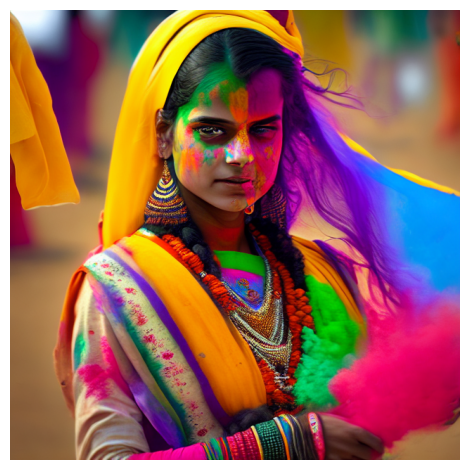

In [25]:
generate_image(pipe, prompt, params)

  0%|          | 0/100 [00:00<?, ?it/s]

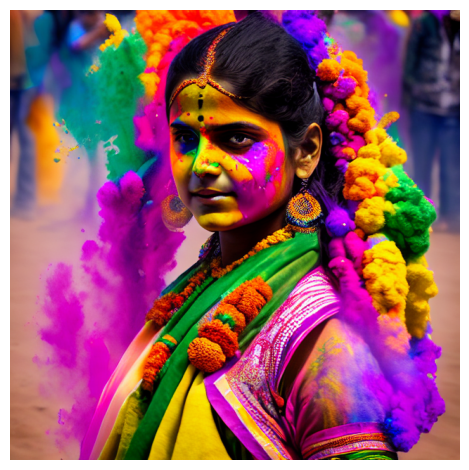

In [26]:
#num interface steps
params = {"num_inference_steps": 100}

generate_image(pipe, prompt, params)

  0%|          | 0/50 [00:00<?, ?it/s]

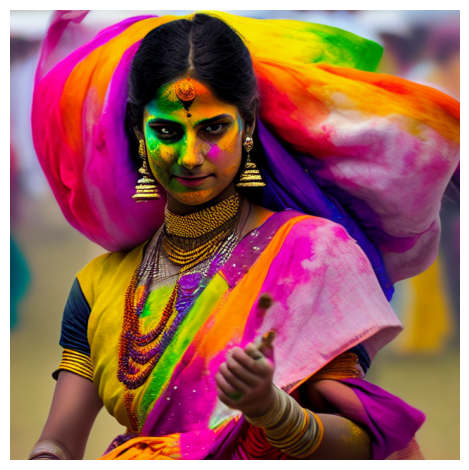

In [27]:
#height width
params = {'num_interface_steps' : 100}
generate_image(pipe, prompt, params)

  0%|          | 0/50 [00:00<?, ?it/s]

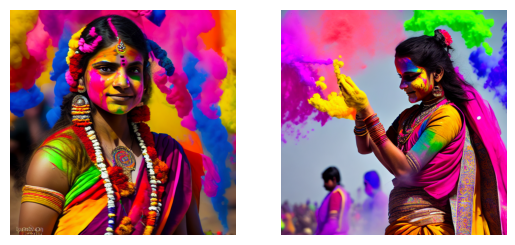

In [28]:
#num_images_per_prompt
params = {'num_interface_steps': 100, 'num_images_per_prompt': 2}
generate_image(pipe, prompt, params)

  0%|          | 0/50 [00:00<?, ?it/s]

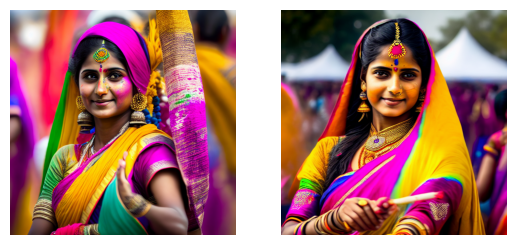

In [30]:
#negative_prompt
params = {'num_interface_steps': 100, 'num_images_per_prompt': 2, 'negative_prompt': 'ugly, distorted, low quality'}
generate_image(pipe, prompt, params)